# Notebook 07: Peak Warnings and Frozen Final Evaluation
**Project F1: Electricity Consumption Analysis and Forecasting in Morocco**

## Objective
Convert the selected demand forecasts into next-day peak-warning schedules, assess the warnings, and evaluate the already-selected fitted forecasters on November–December targets.

## Decisions fixed before test forecast scoring
- One issue at **23:50 on the previous day**, forecasting all **144 next-day readings**. Leads are ten minutes–24 hours. Origin information is frozen within each batch; negligible reporting/computation delay is assumed.
- Keep Notebook 06's validation-MAE selections: weather-enabled boosting for Zone 1, the previous-day baseline for Zone 2, and weather-enabled Ridge for Zone 3.
- Keep the **August-fitted estimators unchanged**. Later eligible measurements update the daily input history, not the fitted parameters. This is a frozen-fit evaluation, not an experiment refitted through October.
- Define a peak as a reading **at or above that series' training 95th percentile**. Fit thresholds on January 9–August 31 labels only, with linear quantile interpolation. Combined demand gets its own threshold, not the sum of zone thresholds.
- Raise a warning when the forecast meets that same fixed threshold. No extra alert margin, bias correction, threshold tuning, or model reselection is performed using test scores.

These thresholds describe historical high demand; they are **not engineering capacity limits or probabilities**. This is a documented project definition, not a requirement quoted from the brief.

## Honest limits of the evaluation
The full file was explored descriptively in earlier notebooks. During planning, a label-support audit also inspected later-window peak counts before any test forecast-error scoring. The 95th-percentile definition was already specified and was not changed after that inspection. We therefore do not claim that test labels or support were completely unseen.

The evaluation plan below is recorded before computing test predictions/errors in this notebook. It is an audit record, not a tamper-proof guarantee against later edits. Test results are reported even if an advanced model underperforms its baseline.

## 1. Setup and Output Paths
Run Notebooks 04–06 first using the project `.venv`. We save figures as PNG/SVG, calculation tables as CSV, forecast-only alert schedules separately from retrospective outcomes, and a frozen evaluation record.

In [1]:
import sys, json, hashlib, importlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import joblib
from threadpoolctl import threadpool_limits
from IPython.display import display

p=Path.cwd().resolve()
ROOT=next(x for x in [p,*p.parents] if (x/'src/config.py').is_file())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
import src.config as cfg
importlib.reload(cfg)
from src.config import PROCESSED_DIR,FIGURES_DIR,TABLES_DIR,MODELS_DIR,ZONES,PEAK_QUANTILE
FIG=FIGURES_DIR/'07_peak_detection_alerts'
TAB=TABLES_DIR/'07_peak_detection_alerts'
EVAL=MODELS_DIR/'07_frozen_evaluation'
for folder in [FIG,TAB,EVAL]:folder.mkdir(parents=True,exist_ok=True)
SERIES=[*ZONES,'total']
LABELS={'zone1':'Zone 1','zone2':'Zone 2','zone3':'Zone 3','total':'Combined'}
METHODS=['baseline','selected']
COLORS={'baseline':'#0072B2','selected':'#D55E00'}
sns.set_theme(style='whitegrid',context='notebook')
plt.rcParams.update({'figure.dpi':110,'svg.fonttype':'none'})
def sha(path):return hashlib.sha256(Path(path).read_bytes()).hexdigest()
def save_table(data,name,index=False):data.to_csv(TAB/f'{name}.csv',index=index,encoding='utf-8')
def figure(fig,name):
    fig.tight_layout()
    for ext in ['png','svg']:fig.savefig(FIG/f'{name}.{ext}',dpi=200,bbox_inches='tight')
    plt.show();plt.close(fig)
print('Python:',sys.executable)
print('Daily issue: previous-day23:50. Model parameters remain frozen at the August fit.')

Python: C:\Users\banda\Desktop\MScBA\Semester_1\Descriptive Analytics & Data Visualization\Project\.venv\Scripts\python.exe
Daily issue: previous-day23:50. Model parameters remain frozen at the August fit.


## 2. Verify the Feature and Model Contracts
Check source hashes, model-selection files, shared daily origins, and source timing. Load only the already-selected estimators; do not search across candidates again.

We reconstruct the original per-zone baseline as a separate comparator. Combined predictions are sums of simultaneous zone predictions in both methods.

In [2]:
mp=PROCESSED_DIR/'tetuan_features_daily_batch_manifest.json'
manifest=json.loads(mp.read_text(encoding='utf-8'))
feature_path=PROCESSED_DIR/manifest['feature_file']
clean_path=PROCESSED_DIR/manifest['source_file']
assert manifest['design_id']=='daily_batch_2350'
assert sha(feature_path)==manifest['feature_sha256'] and sha(clean_path)==manifest['source_sha256']
selection_path=MODELS_DIR/'06_daily_batch/model_selection_daily_batch.json'
selection=json.loads(selection_path.read_text(encoding='utf-8'))
baseline_path=MODELS_DIR/'05_baselines_daily_batch/baseline_selection_daily_batch.json'
baseline_contract=json.loads(baseline_path.read_text(encoding='utf-8'))
assert selection['feature_manifest_sha256']==sha(mp)==baseline_contract['feature_manifest_sha256']
assert selection['baseline_selection']==baseline_contract['selected_baseline_by_zone']
choices=selection['selected_by_zone']
panel=pd.read_parquet(feature_path)
train=panel.loc[panel.split.eq('train')].copy()
validation=panel.loc[panel.split.eq('validation')].copy()
assert len(train)==33840 and len(validation)==8784
assert panel.groupby(panel.target_time.dt.normalize()).size().eq(144).all()
assert panel.groupby(panel.target_time.dt.normalize()).origin_time.nunique().eq(1).all()
assert panel.origin_time.eq(panel.target_time.dt.normalize()-pd.Timedelta(minutes=10)).all()
assert panel.lead_steps.between(1,144).all()
bundles={};model_hashes={}
for zone in ZONES:
    candidate=choices[zone]
    if candidate!='baseline':
        path=MODELS_DIR/'06_daily_batch'/f'{candidate}_{zone}.joblib'
        model_hashes[zone]={'relative_path':str(path.relative_to(ROOT)),'sha256':sha(path)}
        bundle=joblib.load(path)
        assert bundle['design_id']==manifest['design_id']
        assert set(bundle['feature_columns']).issubset(manifest['feature_columns'])
        assert bundle['anchor_column']==f'{zone}_target_lag_1d'
        assert pd.Timestamp(bundle['fit_latest_label'])==train.target_time.max()
        bundles[zone]=bundle

def actual_frame(block):
    frame=block.set_index('target_time')[[f'y_{z}' for z in ZONES]].rename(columns={f'y_{z}':z for z in ZONES})
    frame['total']=frame[ZONES].sum(axis=1)
    return frame

def predict_block(block):
    index=pd.DatetimeIndex(block.target_time,name='target_time')
    reference=pd.DataFrame(index=index)
    suffixes={'origin_persistence':'at_origin','previous_day':'target_lag_1d',
              'previous_week':'target_lag_7d','seven_day_mean':'previous7_same_clock_mean'}
    for zone in ZONES:
        rule=baseline_contract['selected_baseline_by_zone'][zone]
        assert rule in suffixes,'This frozen plan expects a saved measurement-based baseline.'
        reference[zone]=block[f'{zone}_{suffixes[rule]}'].to_numpy()
    selected=reference.copy()
    for zone,bundle in bundles.items():
        assert block.origin_time.ge(pd.Timestamp(bundle['fit_latest_label'])).all()
        with threadpool_limits(limits=2):
            correction=bundle['model'].predict(block[bundle['feature_columns']])
        selected[zone]=np.maximum(0,block[bundle['anchor_column']].to_numpy()+correction)
    for frame in [reference,selected]:
        frame['total']=frame[ZONES].sum(axis=1)
        assert np.isfinite(frame.to_numpy()).all()
    return {'baseline':reference,'selected':selected}

val_predictions=predict_block(validation)
val_actual=actual_frame(validation)
saved=pd.read_parquet(PROCESSED_DIR/'model_validation_daily_batch.parquet')
for method,candidate in [('baseline','baseline'),('selected','selected')]:
    previous=saved.loc[saved.candidate.eq(candidate)].pivot(index='target_time',columns='series',values='prediction').reindex(index=val_actual.index,columns=SERIES)
    assert np.allclose(previous,val_predictions[method])
print('Selected validation predictions replayed exactly within numerical tolerance.')

Selected validation predictions replayed exactly within numerical tolerance.


## 3. Fit Historical Peak Thresholds on Training Labels Only
Use each series' 95th percentile from the same training-label window used for model fitting. The `>=` rule includes ties, so the training positive count need not be exactly 5%.

The threshold does not move with the evaluation period, hour, or month. Consequently, later periods can contain much more or much less than 5% peaks, including zero. A threshold recalculated on test labels would answer a different question and leak information into the definition.

,series,threshold,quantile,training_peak_readings,training_readings,training_peak_pct
0,zone1,45037.398,0.95,1692,33840,5.000
1,zone2,29206.329,0.95,1693,33840,5.003
2,zone3,32397.027,0.95,1692,33840,5.000
3,total,103272.934,0.95,1692,33840,5.000


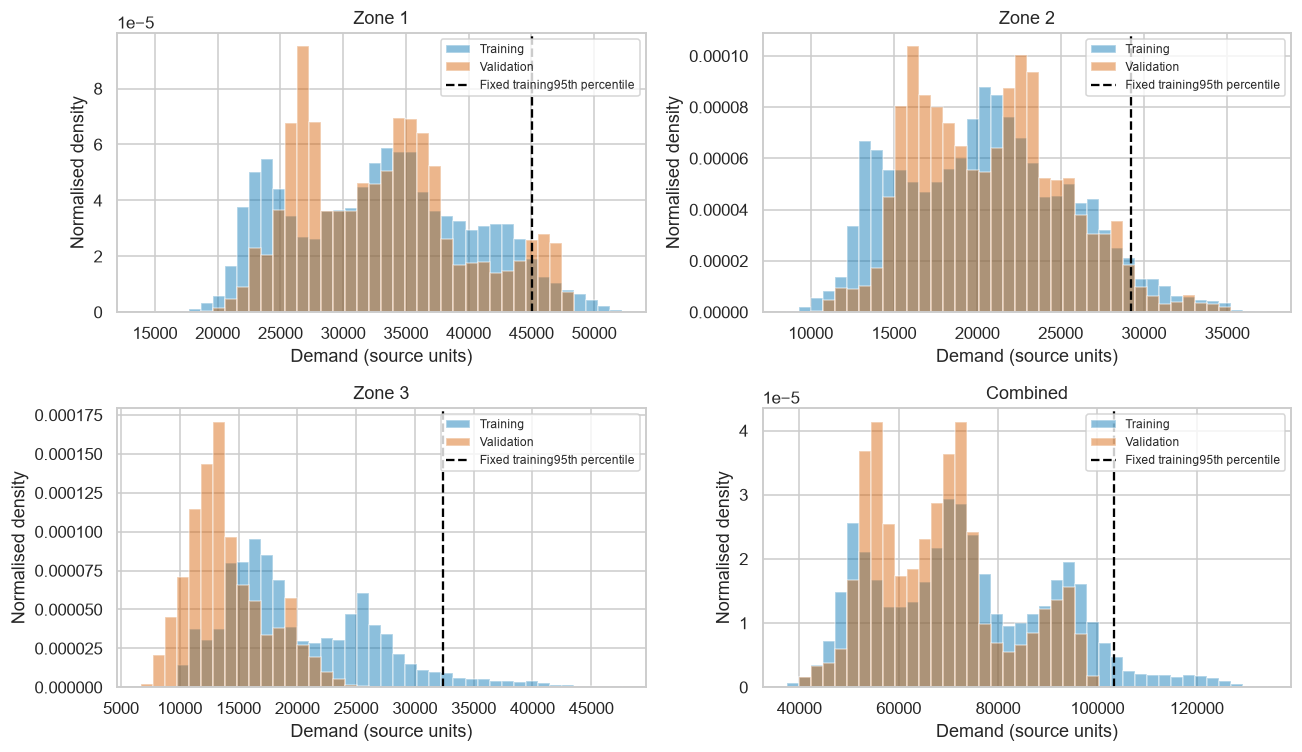

In [3]:
assert np.isclose(PEAK_QUANTILE,.95),'This evaluation uses the predeclared training95th-percentile definition.'
train_actual=actual_frame(train)
thresholds=train_actual.quantile(.95,interpolation='linear')
threshold_table=pd.DataFrame({'series':SERIES,'threshold':thresholds.reindex(SERIES).to_numpy()})
threshold_table['quantile']=.95
threshold_table['training_peak_readings']=[int(train_actual[z].ge(thresholds[z]).sum()) for z in SERIES]
threshold_table['training_readings']=len(train)
threshold_table['training_peak_pct']=threshold_table.training_peak_readings/len(train)*100
save_table(threshold_table,'01_training_peak_thresholds')
display(threshold_table.round(3))

fig,axes=plt.subplots(2,2,figsize=(12,7))
for ax,zone in zip(axes.flat,SERIES):
    bins=np.histogram_bin_edges(np.r_[train_actual[zone],val_actual[zone]],bins=40)
    ax.hist(train_actual[zone],bins=bins,density=True,alpha=.45,color='#0072B2',label='Training')
    ax.hist(val_actual[zone],bins=bins,density=True,alpha=.45,color='#D55E00',label='Validation')
    ax.axvline(thresholds[zone],color='black',linestyle='--',label='Fixed training95th percentile')
    ax.set(title=LABELS[zone],xlabel='Demand (source units)',ylabel='Normalised density')
    ax.legend(fontsize=8)
figure(fig,'01_training_thresholds_and_validation_distributions')

### Interpretation: What Counts as a Peak
The thresholds are approximately **45,037.40** for Zone 1, **29,206.33** for Zone 2, **32,397.03** for Zone 3, and **103,272.93 source units** for combined demand.

The combined threshold is derived from simultaneous combined training demand. It is not the sum of the other thresholds, and zone-level warnings do not mechanically imply a combined warning.

Under this fixed definition, validation contains 589 peak readings in Zone 1 and 280 in Zone 2, with none in Zone 3 or combined demand. That limits what validation can establish about peak sensitivity in those series. We keep the stated definition rather than lowering a threshold to manufacture evaluation cases.

## 4. Define Point-Level and Daily Warning Metrics
At each timestamp, compare actual and forecast demand with the same training threshold:
- **TP:** actual peak and warning.
- **FP:** warning without an actual peak.
- **FN:** actual peak without a warning.
- **TN:** neither a peak nor a warning.

Precision is TP/(TP+FP); recall is TP/(TP+FN). Undefined ratios are `NA`, not silently replaced with zero. F1 uses2TP/(2TP+FP+FN), with `NA` if that denominator is zero. If actual peaks are absent, recall is undefined; false warnings can still be counted. High accuracy in an all-negative period does not demonstrate useful peak anticipation.

We also calculate **daily-any-peak** metrics: did any warning and any actual peak occur during the same target day? This coarser measure does not require correct ten-minute timing and is reported separately.

Definitions are consistent with the [scikit-learn confusion-matrix documentation](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html). See also its [precision/recall support and undefined-metric discussion](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_recall_fscore_support.html). We implement the ratios explicitly so their denominators remain visible.

In [4]:
def ratio(a,b):return float(a/b) if b else np.nan

def alert_metrics(truth,warning):
    truth=np.asarray(truth,dtype=bool);warning=np.asarray(warning,dtype=bool)
    assert truth.ndim==warning.ndim==1 and truth.shape==warning.shape and truth.size>0
    tp=int((truth&warning).sum());fp=int((~truth&warning).sum())
    fn=int((truth&~warning).sum());tn=int((~truth&~warning).sum())
    return {'n':len(truth),'actual_peaks':tp+fn,'warnings':tp+fp,'TP':tp,'FP':fp,'FN':fn,'TN':tn,
        'precision':ratio(tp,tp+fp),'recall':ratio(tp,tp+fn),'F1':ratio(2*tp,2*tp+fp+fn),
        'false_positive_rate':ratio(fp,fp+tn),'accuracy':ratio(tp+tn,len(truth)),
        'peak_prevalence_pct':100*ratio(tp+fn,len(truth))}

toy=alert_metrics([1,1,0,0],[1,0,1,0])
assert toy['TP']==toy['FP']==toy['FN']==toy['TN']==1
assert toy['precision']==toy['recall']==toy['F1']==.5
empty=alert_metrics([0,0],[0,0])
assert np.isnan(empty['precision']) and np.isnan(empty['recall']) and np.isnan(empty['F1'])
miss=alert_metrics([1,0],[0,0]);assert miss['recall']==0 and miss['F1']==0

def evaluate_alerts(actual,predictions,period):
    point_rows=[];day_rows=[]
    for method,forecast in predictions.items():
        pd.testing.assert_index_equal(actual.index,forecast.index)
        for zone in SERIES:
            truth=actual[zone].ge(thresholds[zone])
            warning=forecast[zone].ge(thresholds[zone])
            point_rows.append({'period':period,'method':method,'series':zone,**alert_metrics(truth,warning)})
            day_truth=truth.groupby(truth.index.normalize()).any()
            day_warning=warning.groupby(warning.index.normalize()).any()
            day_rows.append({'period':period,'method':method,'series':zone,**alert_metrics(day_truth,day_warning)})
    return pd.DataFrame(point_rows),pd.DataFrame(day_rows)

def confusion_figure(scores,name,title):
    fig,axes=plt.subplots(2,4,figsize=(15,7))
    for i,method in enumerate(METHODS):
        for j,zone in enumerate(SERIES):
            row=scores.loc[scores.method.eq(method)&scores.series.eq(zone)].iloc[0]
            matrix=np.array([[row.TN,row.FP],[row.FN,row.TP]],dtype=int)
            sns.heatmap(matrix,ax=axes[i,j],annot=True,fmt='d',cmap='Blues',vmin=0,vmax=row.n,
                cbar=False,xticklabels=['No warning','Warning'],yticklabels=['No peak','Peak'])
            axes[i,j].set(title=f'{method}: {LABELS[zone]}',xlabel='Forecast class',ylabel='Actual class')
            axes[i,j].tick_params(axis='y',rotation=0)
    fig.suptitle(title,y=1.02)
    figure(fig,name)

def precision_recall_figure(scores,name,title):
    fig,axes=plt.subplots(1,2,figsize=(13,4.7))
    x=np.arange(4)
    for ax,metric in zip(axes,['precision','recall']):
        for i,method in enumerate(METHODS):
            values=scores.loc[scores.method.eq(method)].set_index('series').reindex(SERIES)[metric]
            pos=x+(i-.5)*.32
            ax.bar(pos,values.to_numpy()*100,width=.3,color=COLORS[method],label=method)
            for px,value in zip(pos,values):
                if pd.isna(value):ax.text(px,3,'NA',ha='center',fontsize=9,rotation=90)
                else:ax.text(px,value*100+2,f'{value*100:.1f}',ha='center',fontsize=8)
        supports=scores.loc[scores.method.eq('selected')].set_index('series').reindex(SERIES).actual_peaks
        ax.set(xticks=x,xticklabels=[f'{LABELS[z]}\n(actual peaks={int(supports[z])})' for z in SERIES],
               ylabel=f'{metric.title()} (%)',title=metric.title(),ylim=(0,115))
        ax.legend(fontsize=9)
    fig.suptitle(title,y=1.02)
    figure(fig,name)

## 5. Validation Warning Diagnostics
Apply the already-fixed threshold to the replayed validation forecasts. This is a diagnostic of the models selected for demand MAE, not a separate alert-optimisation exercise.

No threshold or model is altered after inspecting these warning metrics. Lower average forecast error does not guarantee higher peak recall.

The selected combination was chosen using the whole validation window. Its validation schedules are therefore retrospective selection diagnostics, not a claim that this combination was already selected at every original September issue. The final test uses choices established before its period.

,period,method,series,n,actual_peaks,warnings,TP,FP,FN,TN,precision,recall,F1,false_positive_rate,accuracy,peak_prevalence_pct
0,validation,baseline,zone1,8784,589,605,464,141,125,8054,0.767,0.788,0.777,0.017,0.970,6.705
1,validation,baseline,zone2,8784,280,252,174,78,106,8426,0.690,0.621,0.654,0.009,0.979,3.188
2,validation,baseline,zone3,8784,0,0,0,0,0,8784,NaN,NaN,NaN,0.000,1.000,0.000
3,validation,baseline,total,8784,0,0,0,0,0,8784,NaN,NaN,NaN,0.000,1.000,0.000
4,validation,selected,zone1,8784,589,516,433,83,156,8112,0.839,0.735,0.784,0.010,0.973,6.705
5,validation,selected,zone2,8784,280,252,174,78,106,8426,0.690,0.621,0.654,0.009,0.979,3.188
6,validation,selected,zone3,8784,0,0,0,0,0,8784,NaN,NaN,NaN,0.000,1.000,0.000
7,validation,selected,total,8784,0,0,0,0,0,8784,NaN,NaN,NaN,0.000,1.000,0.000


,period,method,series,n,actual_peaks,warnings,TP,FP,FN,TN,precision,recall,F1,false_positive_rate,accuracy,peak_prevalence_pct
0,validation,baseline,zone1,61,45,46,41,5,4,11,0.891,0.911,0.901,0.312,0.852,73.770
1,validation,baseline,zone2,61,18,17,12,5,6,38,0.706,0.667,0.686,0.116,0.820,29.508
2,validation,baseline,zone3,61,0,0,0,0,0,61,NaN,NaN,NaN,0.000,1.000,0.000
3,validation,baseline,total,61,0,0,0,0,0,61,NaN,NaN,NaN,0.000,1.000,0.000
4,validation,selected,zone1,61,45,42,37,5,8,11,0.881,0.822,0.851,0.312,0.787,73.770
5,validation,selected,zone2,61,18,17,12,5,6,38,0.706,0.667,0.686,0.116,0.820,29.508
6,validation,selected,zone3,61,0,0,0,0,0,61,NaN,NaN,NaN,0.000,1.000,0.000
7,validation,selected,total,61,0,0,0,0,0,61,NaN,NaN,NaN,0.000,1.000,0.000


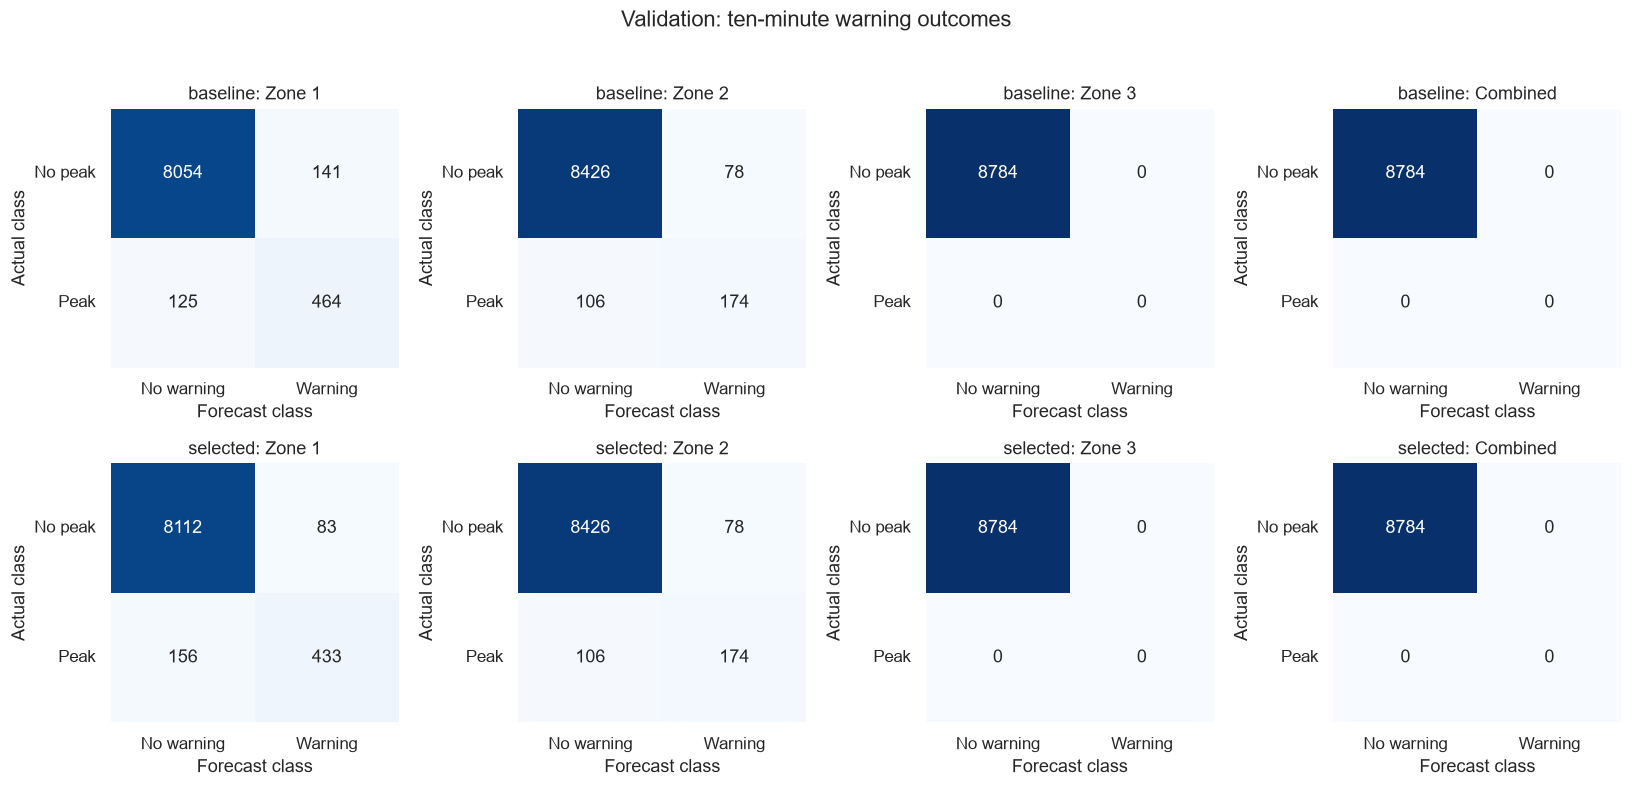

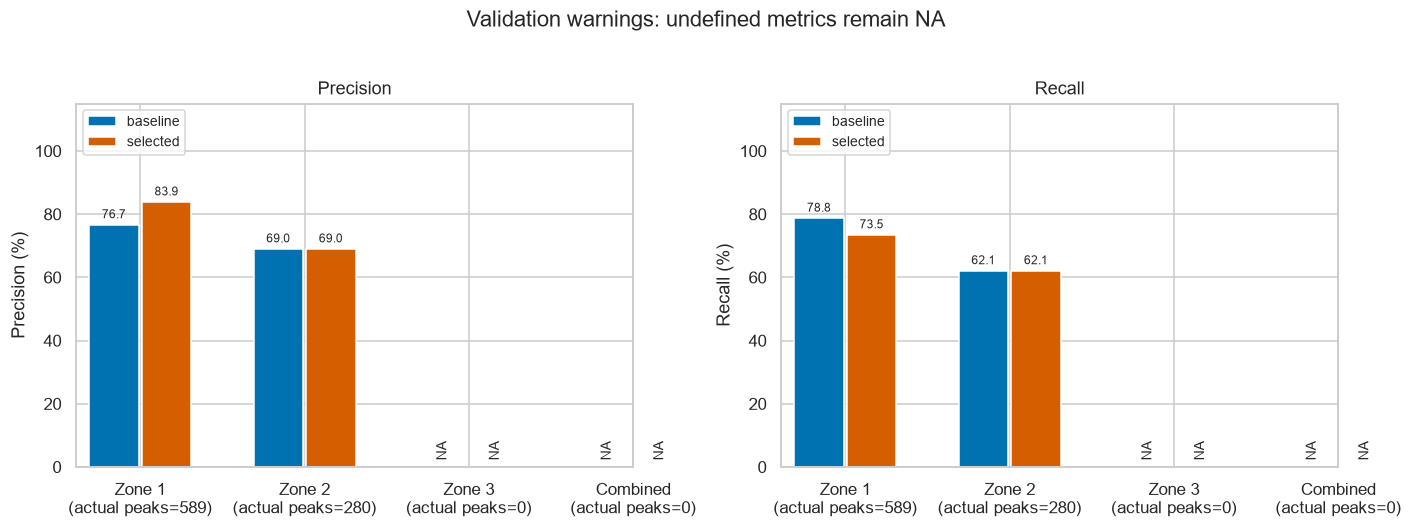

In [5]:
val_points,val_days=evaluate_alerts(val_actual,val_predictions,'validation')
save_table(val_points,'02_validation_point_alert_metrics')
save_table(val_days,'03_validation_daily_any_peak_metrics')
display(val_points.round(3))
display(val_days.round(3))
confusion_figure(val_points,'02_validation_confusion_matrices','Validation: ten-minute warning outcomes')
precision_recall_figure(val_points,'03_validation_precision_recall','Validation warnings: undefined metrics remain NA')

### Interpretation: Validation Precision–Recall Trade-off
For Zone 1, the selected forecast raises precision from **76.69% to 83.91%**, but recall falls from **78.78% to 73.51%**. False warnings fall from 141 to 83, while missed actual peaks rise from 125 to 156.

This is a genuine trade-off: better demand MAE did not improve every warning metric. The models were selected for forecast MAE, not optimised for peak recall. We retain the declared threshold and report both outcomes.

Zone 2's validation precision is **69.05%** and recall **62.14%** for both methods because its selected forecaster is the same baseline. Zone 3 and combined demand have no actual validation peaks and no warnings; their precision, recall and F1 are undefined, not perfect.

## 6. Record the Frozen Final Evaluation Plan
The final test assesses these exact August-fitted estimators, without refitting on validation outcomes. The baseline comparison uses the same rules and test timestamps.

The plan records selected-model hashes, source/feature hashes, fixed thresholds, the daily forecast contract, and the scoring period **November 1–December 30**. A re-run must match an existing plan instead of silently overwriting it with changed choices.

This lock precedes test predictions and forecast-error calculations in the code. It does not erase earlier descriptive or label-support exposure. No claim of a completely untouched test dataset is made.

In [6]:
frozen_plan={
    'design_id':manifest['design_id'],'issue_clock':manifest['issue_clock'],
    'parameter_policy':'Use saved August-fitted estimators unchanged; daily input history advances',
    'selected_models':choices,'selected_baseline_rules':baseline_contract['selected_baseline_by_zone'],
    'fit_latest_label':str(train.target_time.max()),'model_artifacts':model_hashes,
    'feature_manifest_sha256':sha(mp),'feature_sha256':sha(feature_path),'clean_source_sha256':sha(clean_path),
    'model_selection_sha256':sha(selection_path),'baseline_selection_sha256':sha(baseline_path),
    'peak_quantile':.95,'quantile_interpolation':'linear','peak_comparison':'>=',
    'threshold_training_first_target':str(train.target_time.min()),
    'threshold_training_last_target':str(train.target_time.max()),'thresholds':thresholds.to_dict(),
    'test_first_target':'2017-11-01 00:00:00','test_last_target':'2017-12-30 23:50:00',
    'test_rows':8640,'test_batches':60,'no_test_reselection':True,
    'prior_full_file_descriptive_exposure':True,'prior_label_support_audit':True,
    'alert_rule':'forecast >= training threshold; no tuned margin or bias correction',
    'timing_metrics':'Exact ten-minute point and separate same-calendar-day any-peak',
}
plan_path=EVAL/'frozen_plan_daily_batch.json'
if plan_path.exists():
    assert json.loads(plan_path.read_text(encoding='utf-8'))==frozen_plan,'Existing evaluation plan differs. Do not silently retune an already-scored test.'
else:
    plan_path.write_text(json.dumps(frozen_plan,indent=2,allow_nan=False),encoding='utf-8')
plan_hash=sha(plan_path)
assert frozen_plan==json.loads(plan_path.read_text(encoding='utf-8'))
print('Frozen evaluation plan saved/verified before test forecast scoring:',plan_path)

Frozen evaluation plan saved/verified before test forecast scoring: C:\Users\banda\Desktop\MScBA\Semester_1\Descriptive Analytics & Data Visualization\Project\outputs\models\07_frozen_evaluation\frozen_plan_daily_batch.json


## 7. Generate Final Test Forecasts With the Frozen Models
Forecast all 60 test days, with one common origin per daily batch. Latest fitting labels are earlier than those issues. Earlier test-day observations become eligible history only for subsequent daily batches.

All choices are inherited from the frozen record. We do not refit, recalibrate, or switch models based on test outcomes.

In [7]:
assert sha(plan_path)==plan_hash and sha(selection_path)==frozen_plan['model_selection_sha256']
for record in model_hashes.values():assert sha(ROOT/record['relative_path'])==record['sha256']
test=panel.loc[panel.split.eq('test')].copy()
assert len(test)==8640
assert test.target_time.min()==pd.Timestamp(frozen_plan['test_first_target'])
assert test.target_time.max()==pd.Timestamp(frozen_plan['test_last_target'])
assert test.origin_time.ge(train.target_time.max()).all()
assert test.groupby(test.target_time.dt.normalize()).size().eq(144).all()
assert test.groupby(test.target_time.dt.normalize()).origin_time.nunique().eq(1).all()
test_predictions=predict_block(test)
test_actual=actual_frame(test)
for forecast in test_predictions.values():
    pd.testing.assert_index_equal(forecast.index,test_actual.index)
    assert np.allclose(forecast[ZONES].sum(axis=1),forecast.total)
print('Generated60 frozen-parameter daily forecast batches for the final period.')

Generated60 frozen-parameter daily forecast batches for the final period.


## 8. Final Demand-Forecast Accuracy
Calculate the same MAE, MSE, RMSE, MAPE, WAPE, and signed bias used previously. MAE remains the primary regression comparison, but all results are reported even when RMSE or a zone's MAE worsens.

We compare the selected combination against the Notebook 05 selected per-zone baseline, not against the weakest candidate.

,period,method,series,n,MAE,MSE,RMSE,MAPE_pct,WAPE_pct,bias,MAE_improvement_vs_baseline_pct,RMSE_change_vs_baseline_pct
8,test,baseline,zone1,8640,977.309,2.155560e+06,1468.182,3.418,3.369,39.305,0.000,0.000
9,test,baseline,zone2,8640,1132.873,2.935196e+06,1713.241,5.105,4.829,5.245,0.000,0.000
10,test,baseline,zone3,8640,854.125,1.928279e+06,1388.625,7.100,7.145,64.543,0.000,0.000
11,test,baseline,total,8640,2159.186,1.046471e+07,3234.920,3.456,3.351,109.093,0.000,0.000
12,test,selected,zone1,8640,2444.484,9.651590e+06,3106.701,8.278,8.425,2310.875,-150.124,111.602
13,test,selected,zone2,8640,1132.873,2.935196e+06,1713.241,5.105,4.829,5.245,0.000,0.000
14,test,selected,zone3,8640,1694.588,3.935227e+06,1983.741,14.521,14.176,-1611.846,-98.400,42.856
15,test,selected,total,8640,2512.191,1.144465e+07,3382.994,3.938,3.899,704.275,-16.349,4.577


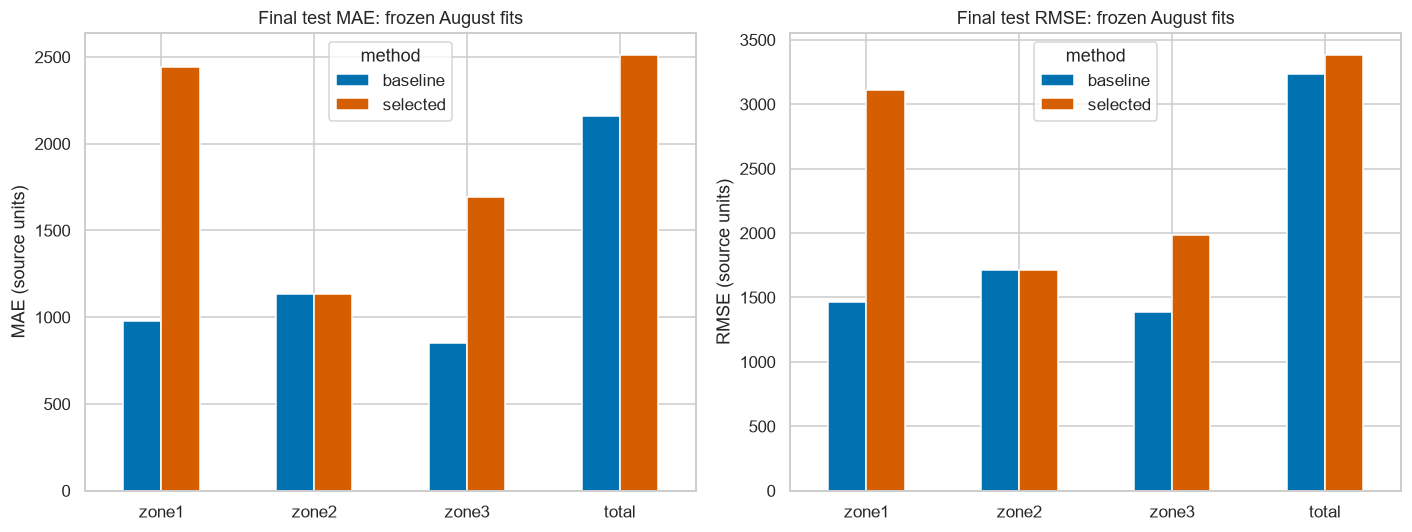

In [8]:
def forecast_metrics(actual,predicted):
    y=np.asarray(actual,dtype=float);p=np.asarray(predicted,dtype=float)
    assert y.ndim==p.ndim==1 and y.shape==p.shape and (y>0).all()
    assert np.isfinite(y).all() and np.isfinite(p).all()
    error=p-y;mse=np.mean(error**2)
    return {'n':len(y),'MAE':np.abs(error).mean(),'MSE':mse,'RMSE':np.sqrt(mse),
        'MAPE_pct':np.mean(np.abs(error)/y)*100,'WAPE_pct':np.abs(error).sum()/y.sum()*100,'bias':error.mean()}
regression_rows=[]
for period,actual,predictions in [('validation',val_actual,val_predictions),('test',test_actual,test_predictions)]:
    for method,forecast in predictions.items():
        for zone in SERIES:
            regression_rows.append({'period':period,'method':method,'series':zone,**forecast_metrics(actual[zone],forecast[zone])})
regression=pd.DataFrame(regression_rows)
test_scores=regression.loc[regression.period.eq('test')].copy()
reference=test_scores.loc[test_scores.method.eq('baseline')].set_index('series')
test_scores['MAE_improvement_vs_baseline_pct']=[100*(1-r.MAE/reference.loc[r.series,'MAE']) for r in test_scores.itertuples()]
test_scores['RMSE_change_vs_baseline_pct']=[100*(r.RMSE/reference.loc[r.series,'RMSE']-1) for r in test_scores.itertuples()]
save_table(regression,'04_validation_and_test_forecast_metrics')
save_table(test_scores,'05_final_test_forecast_metrics')
display(test_scores.round(3))
fig,axes=plt.subplots(1,2,figsize=(13,5))
for ax,metric in zip(axes,['MAE','RMSE']):
    table=test_scores.pivot(index='series',columns='method',values=metric).reindex(SERIES)
    table.plot.bar(ax=ax,rot=0,color=[COLORS[m] for m in table.columns])
    ax.set(title=f'Final test {metric}: frozen August fits',xlabel='',ylabel=f'{metric} (source units)')
figure(fig,'04_final_test_forecast_accuracy')

### Interpretation: The Validation Gains Did Not Generalise
On the frozen final test, combined selected-model **MAE is 2,512.19**, compared with the baseline's **2,159.19 source units**: approximately **16.35% worse**. Selected RMSE is **3,382.99**, versus baseline **3,234.92**; selected MAPE is **3.94%**, versus baseline **3.46%**.

The zone results matter:
- Zone 1 selected MAE is **2,444.48**, versus baseline **977.31**, with positive bias approximately **+2,310.87**.
- Zone 2 remains the identical baseline, with MAE **1,132.87**.
- Zone 3 selected MAE is **1,694.59**, versus baseline **854.13**, with negative bias approximately **−1,611.85**.

Offsetting zone biases make the combined series look less problematic than the individual failures. The frozen August-fitted models did not maintain their validation advantage during this later period. Changes in demand and predictor relationships are plausible explanations, but this comparison does not prove their cause or prove that a refit would solve them.

**We do not change the selected models after this result.** The baseline is the more robust comparator in this observed final window. Any revised modelling experiment would need a transparently labelled new evaluation, not a hidden replacement of the reported test.

## 9. Final Peak-Warning Results and Case Counts
Use the original training thresholds and unchanged warning rule. Always interpret precision and recall alongside the actual-peak and warning counts.

Daily-any-peak scores are separate from ten-minute timing scores. If most days contain peaks, simply warning on many days can produce high daily recall; that is weaker evidence than identifying the right target timestamps.

,period,method,series,n,actual_peaks,warnings,TP,FP,FN,TN,precision,recall,F1,false_positive_rate,accuracy,peak_prevalence_pct
0,test,baseline,zone1,8640,0,0,0,0,0,8640,NaN,NaN,NaN,0.000,1.000,0.000
1,test,baseline,zone2,8640,1595,1595,1461,134,134,6911,0.916,0.916,0.916,0.019,0.969,18.461
2,test,baseline,zone3,8640,0,0,0,0,0,8640,NaN,NaN,NaN,0.000,1.000,0.000
3,test,baseline,total,8640,0,0,0,0,0,8640,NaN,NaN,NaN,0.000,1.000,0.000
4,test,selected,zone1,8640,0,166,0,166,0,8474,0.000,NaN,0.000,0.019,0.981,0.000
5,test,selected,zone2,8640,1595,1595,1461,134,134,6911,0.916,0.916,0.916,0.019,0.969,18.461
6,test,selected,zone3,8640,0,0,0,0,0,8640,NaN,NaN,NaN,0.000,1.000,0.000
7,test,selected,total,8640,0,0,0,0,0,8640,NaN,NaN,NaN,0.000,1.000,0.000


,period,method,series,n,actual_peaks,warnings,TP,FP,FN,TN,precision,recall,F1,false_positive_rate,accuracy,peak_prevalence_pct
0,test,baseline,zone1,60,0,0,0,0,0,60,NaN,NaN,NaN,0.00,1.000,0.000
1,test,baseline,zone2,60,58,58,56,2,2,0,0.966,0.966,0.966,1.00,0.933,96.667
2,test,baseline,zone3,60,0,0,0,0,0,60,NaN,NaN,NaN,0.00,1.000,0.000
3,test,baseline,total,60,0,0,0,0,0,60,NaN,NaN,NaN,0.00,1.000,0.000
4,test,selected,zone1,60,0,15,0,15,0,45,0.000,NaN,0.000,0.25,0.750,0.000
5,test,selected,zone2,60,58,58,56,2,2,0,0.966,0.966,0.966,1.00,0.933,96.667
6,test,selected,zone3,60,0,0,0,0,0,60,NaN,NaN,NaN,0.00,1.000,0.000
7,test,selected,total,60,0,0,0,0,0,60,NaN,NaN,NaN,0.00,1.000,0.000


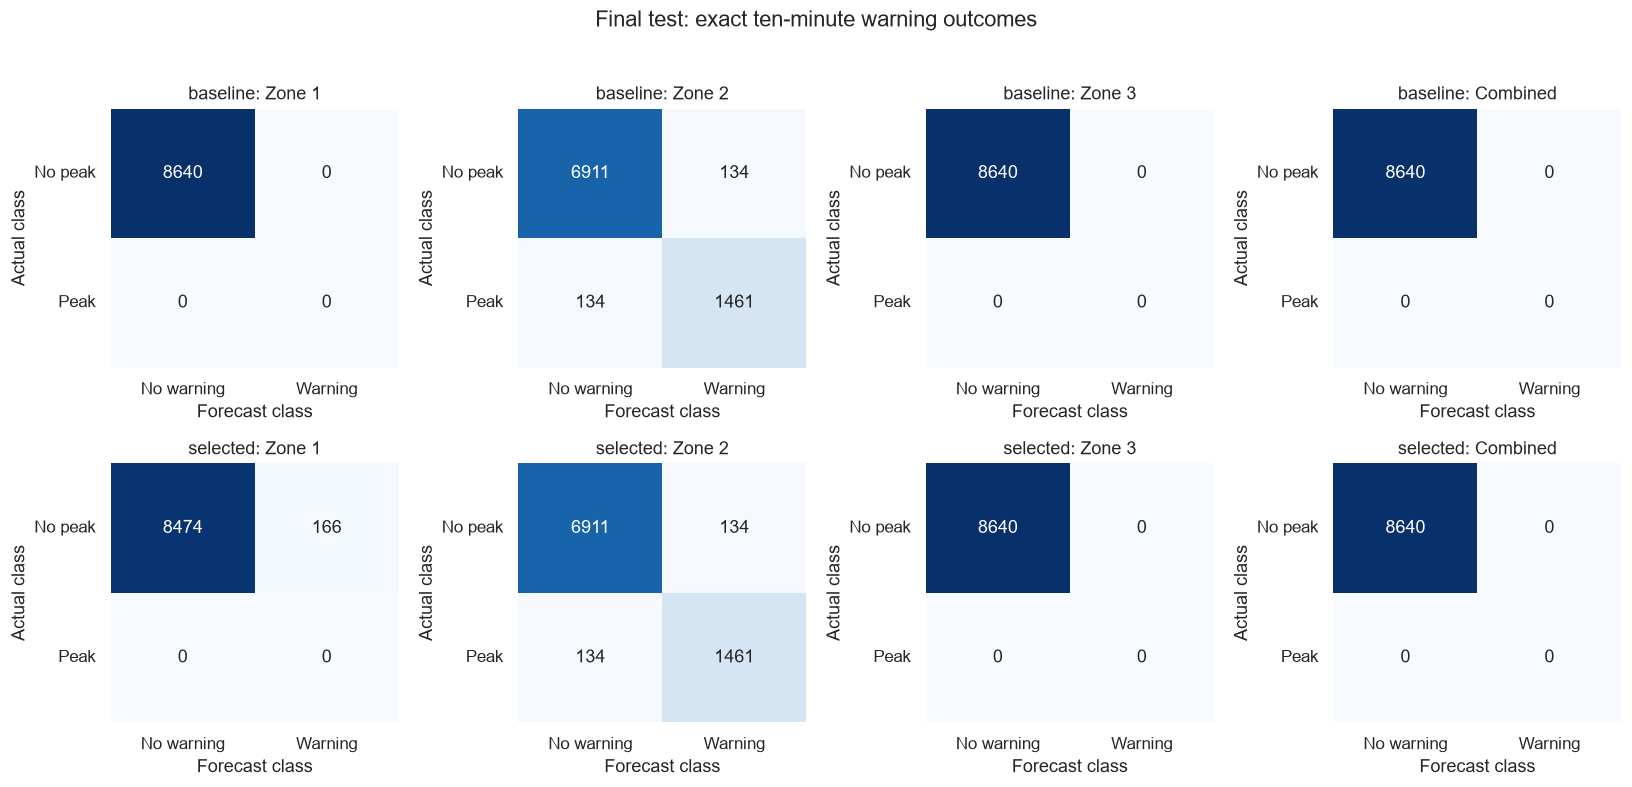

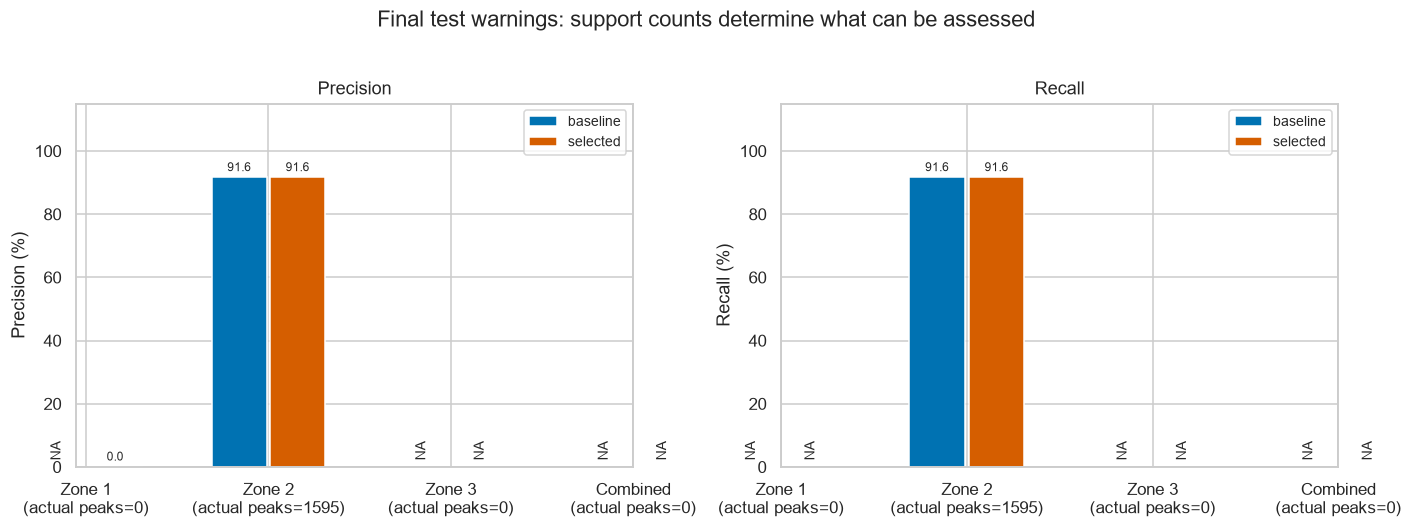

,period,series,readings,peak_readings,peak_days,observed_days,peak_pct
0,training,zone1,33840,1692,120,235,5.000
1,training,zone2,33840,1693,69,235,5.003
2,training,zone3,33840,1692,61,235,5.000
3,training,total,33840,1692,81,235,5.000
4,validation,zone1,8784,589,45,61,6.705
5,validation,zone2,8784,280,18,61,3.188
6,validation,zone3,8784,0,0,61,0.000
7,validation,total,8784,0,0,61,0.000
8,test,zone1,8640,0,0,60,0.000
9,test,zone2,8640,1595,58,60,18.461


In [9]:
test_points,test_days=evaluate_alerts(test_actual,test_predictions,'test')
save_table(test_points,'06_final_test_point_alert_metrics')
save_table(test_days,'07_final_test_daily_any_peak_metrics')
display(test_points.round(3))
display(test_days.round(3))
confusion_figure(test_points,'05_test_confusion_matrices','Final test: exact ten-minute warning outcomes')
precision_recall_figure(test_points,'06_test_precision_recall','Final test warnings: support counts determine what can be assessed')
support=[]
for period,actual in [('training',train_actual),('validation',val_actual),('test',test_actual)]:
    for zone in SERIES:
        flags=actual[zone].ge(thresholds[zone])
        support.append({'period':period,'series':zone,'readings':len(flags),'peak_readings':int(flags.sum()),
            'peak_days':int(flags.groupby(flags.index.normalize()).any().sum()),
            'observed_days':flags.index.normalize().nunique(),'peak_pct':flags.mean()*100})
support=pd.DataFrame(support)
save_table(support,'08_peak_support_by_period')
display(support.round(3))

### Interpretation: Peak Evidence Is Concentrated in Zone 2
Only Zone 2 has actual final-test peaks under the frozen training thresholds: **1,595 readings**. Both methods detect **1,461**, miss **134**, and issue **134 false warnings**. Precision and recall are both approximately **91.60%**, and F1 is approximately **0.916**.

These identical results come from the **previous-day baseline**, which was retained for Zone 2. They do not demonstrate an advanced-model gain in peak warnings.

Zones 1 and3 and combined demand have no actual test peaks. Their recall is therefore undefined. The selected Zone 1 model nevertheless produces **166 false warnings** across 15 days: precision and F1 are zero, while recall remains undefined. Zone 3 and combined demand issue no warnings, so their precision and F1 are also undefined.

The fixed Zone 2 threshold is exceeded by **18.46%** of test readings, rather than 5%, because the threshold was fitted in a different historical period. Recomputing its percentile on the test data would conceal that change and alter the predeclared question.

## 10. Visualise Warning Timing in the Series With Test Peak Cases
Display Zone 2 because it has actual peaks in the test period under the fixed definition. The score tables still include every zone and combined demand.

The first plot uses the fixed first seven test days, November 1–7. Predicted warning markers sit on the forecast curve; actual peak markers sit on actual demand. This is retrospective evidence, not information that was available at issue.

The heatmaps show all 60 days and144 target slots. They distinguish approximate day-level warnings from precise ten-minute timing.

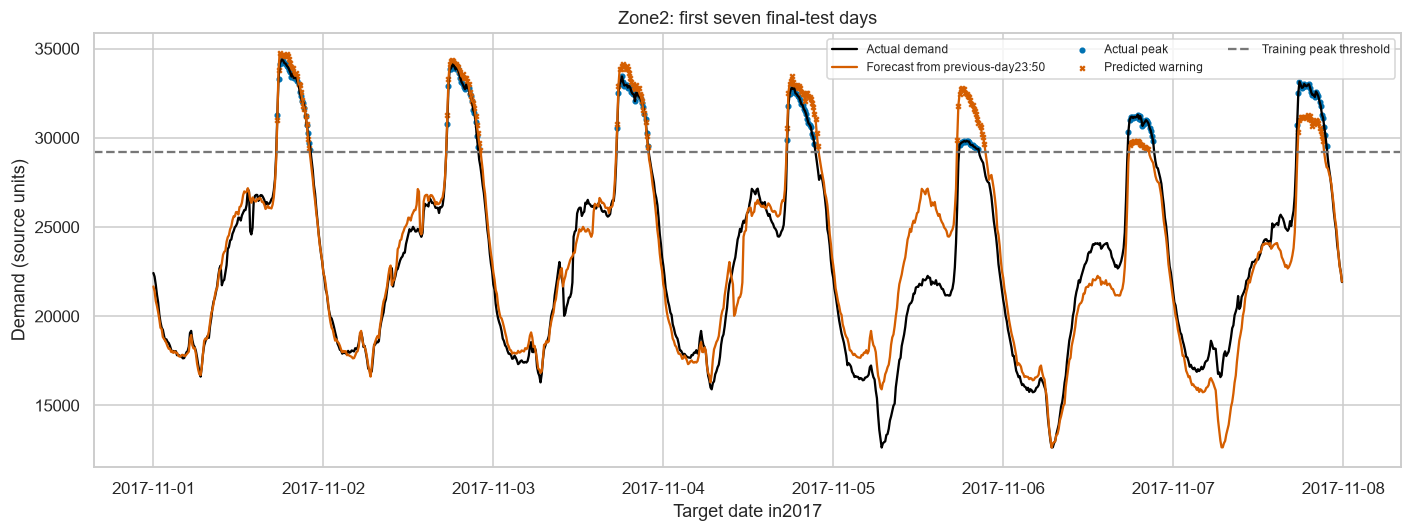

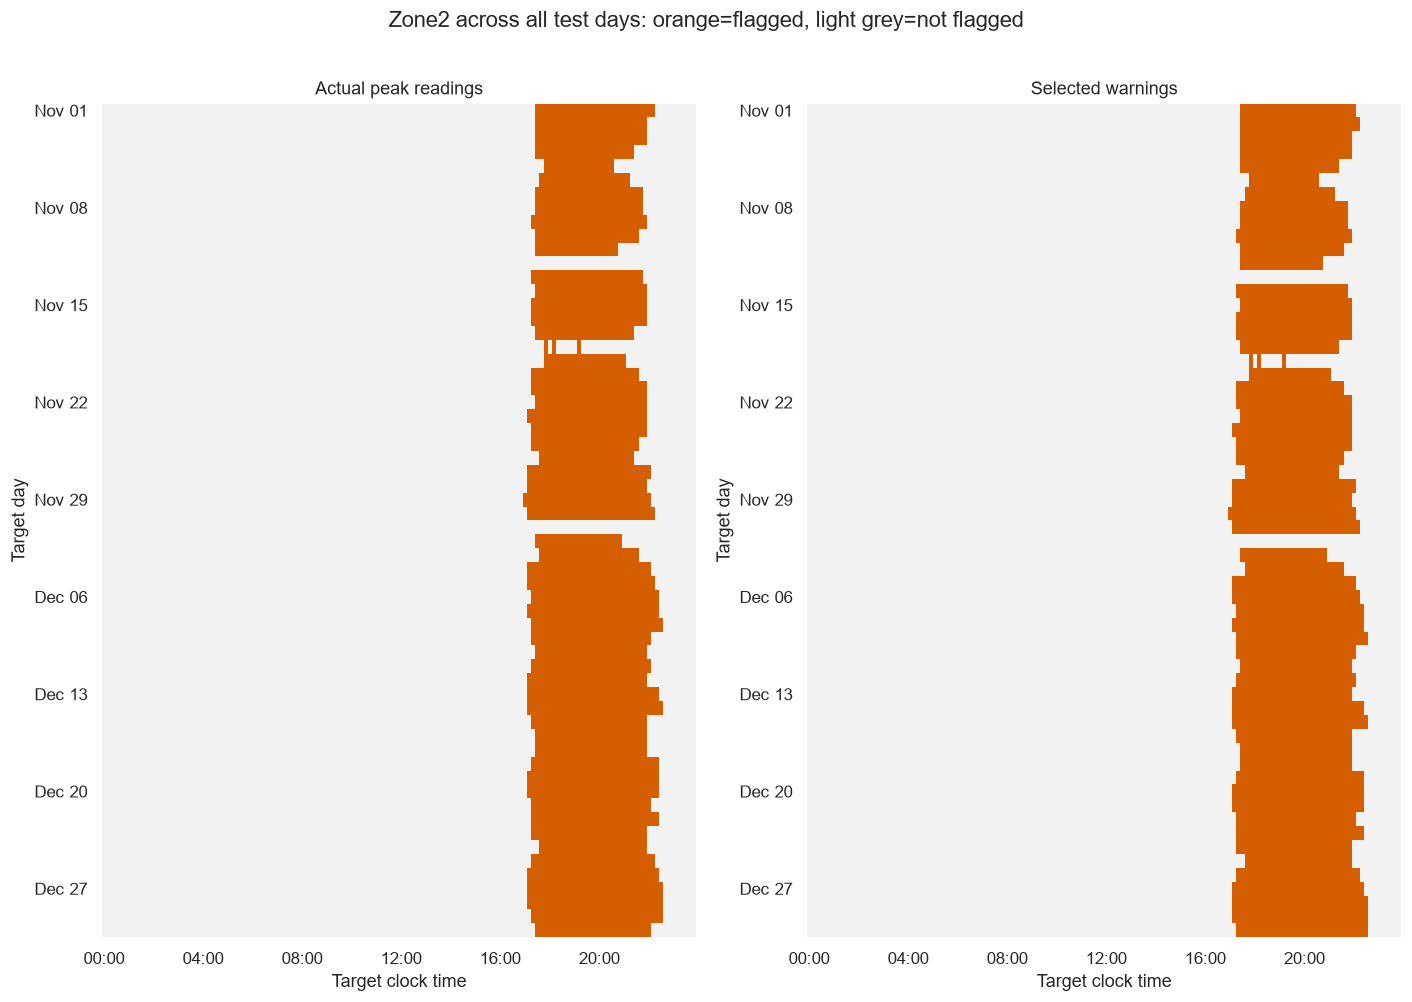

In [10]:
zone='zone2'
first=test_actual.index.min();mask=test_actual.index<first+pd.Timedelta(days=7)
actual_line=test_actual.loc[mask,zone]
predicted_line=test_predictions['selected'].loc[mask,zone]
actual_flags=actual_line.ge(thresholds[zone]);warning_flags=predicted_line.ge(thresholds[zone])
fig,ax=plt.subplots(figsize=(13,5))
ax.plot(actual_line.index,actual_line,color='black',label='Actual demand')
ax.plot(predicted_line.index,predicted_line,color='#D55E00',label='Forecast from previous-day23:50')
ax.scatter(actual_line.index[actual_flags],actual_line[actual_flags],s=9,color='#0072B2',label='Actual peak')
ax.scatter(predicted_line.index[warning_flags],predicted_line[warning_flags],s=9,color='#D55E00',marker='x',label='Predicted warning')
ax.axhline(thresholds[zone],color='#777777',linestyle='--',label='Training peak threshold')
ax.set(title='Zone2: first seven final-test days',xlabel='Target date in2017',ylabel='Demand (source units)')
ax.legend(fontsize=8,ncol=3)
figure(fig,'07_zone2_first_test_week_warnings')

truth=test_actual[zone].ge(thresholds[zone])
warning=test_predictions['selected'][zone].ge(thresholds[zone])
timing=pd.DataFrame({'day':test_actual.index.normalize(),'slot':test.lead_steps.to_numpy()-1,
                     'actual_peak':truth.to_numpy().astype(int),'warning':warning.to_numpy().astype(int)})
fig,axes=plt.subplots(1,2,figsize=(13,9))
for ax,column,title in [(axes[0],'actual_peak','Actual peak readings'),(axes[1],'warning','Selected warnings')]:
    matrix=timing.pivot(index='day',columns='slot',values=column)
    sns.heatmap(matrix,ax=ax,cmap=['#F2F2F2','#D55E00'],vmin=0,vmax=1,cbar=False,
                xticklabels=False,yticklabels=False)
    ax.set_xticks(np.arange(0,144,24)+.5,[f'{h:02d}:00' for h in range(0,24,4)])
    positions=np.arange(0,len(matrix),7)
    ax.set_yticks(positions+.5,matrix.index[positions].strftime('%b %d'))
    ax.set(title=title,xlabel='Target clock time',ylabel='Target day')
    ax.tick_params(axis='y',rotation=0)
fig.suptitle('Zone2 across all test days: orange=flagged, light grey=not flagged',y=1.01)
figure(fig,'08_zone2_test_warning_timing_heatmaps')

## 11. Daily Forecast Errors, Lead Patterns, and Peak Days
The daily charts retain every test day. Lead-slot MAPE remains coupled with target time of day under this once-daily issue schedule.

Daily maximum plots compare maxima within each target day, not necessarily readings at the same ten-minute timestamp. They support the daily-any-peak interpretation and must not be used as evidence of exact timing.

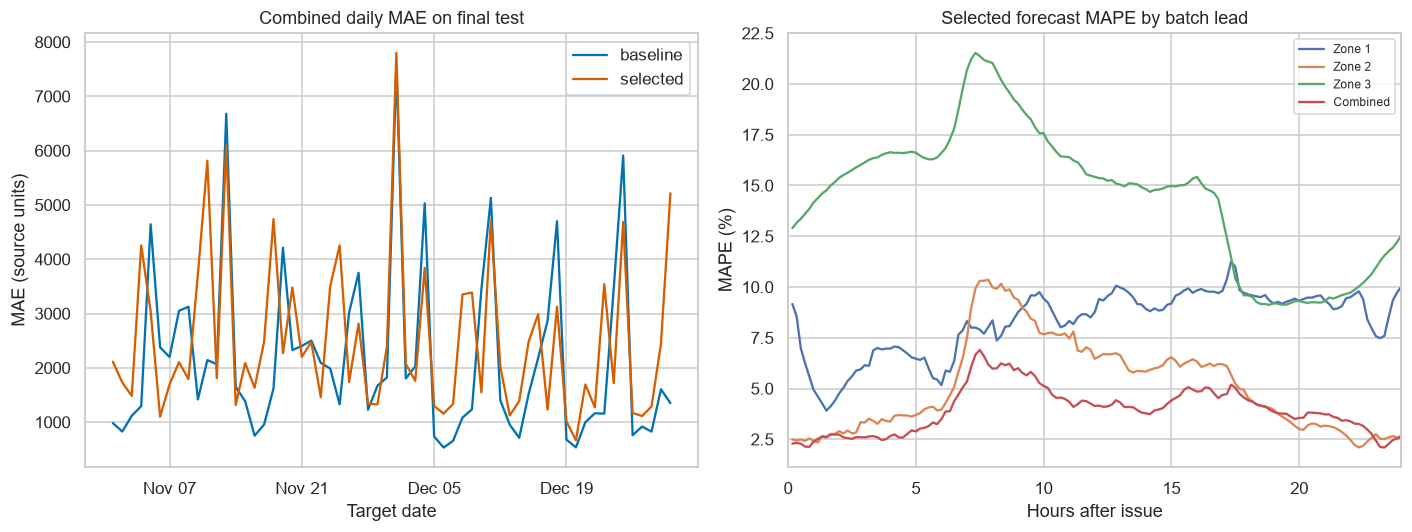

,actual_max,forecast_max,actual_peak_day,warning_day
target_time,,,,
2017-11-01,34385.95,34760.17,True,True
2017-11-02,34121.90,34385.95,True,True
2017-11-03,33437.60,34121.90,True,True
2017-11-04,32790.50,33437.60,True,True
2017-11-05,29826.45,32790.50,True,True
2017-11-06,31291.74,29826.45,True,True
2017-11-07,33151.24,31291.74,True,True
2017-11-08,33526.86,33151.24,True,True
2017-11-09,34333.88,33526.86,True,True


In [11]:
daily_errors={method:(forecast-test_actual).abs().resample('D').mean() for method,forecast in test_predictions.items()}
daily_error_table=pd.concat(daily_errors,names=['method','target_day'])
save_table(daily_error_table,'09_final_test_daily_mae',index=True)
ape=(test_predictions['selected']-test_actual).abs()/test_actual*100
lead_mape=ape.groupby(test.lead_steps.to_numpy()).mean()
lead_mape.index.name='lead_steps'
save_table(lead_mape,'10_final_test_lead_mape',index=True)
fig,axes=plt.subplots(1,2,figsize=(13,5))
for method in METHODS:
    axes[0].plot(daily_errors[method].index,daily_errors[method]['total'],color=COLORS[method],label=method)
axes[0].set(title='Combined daily MAE on final test',xlabel='Target date',ylabel='MAE (source units)')
axes[0].xaxis.set_major_locator(mdates.WeekdayLocator(interval=2))
axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
axes[0].legend()
for zone in SERIES:axes[1].plot(lead_mape.index/6,lead_mape[zone],label=LABELS[zone])
axes[1].set(title='Selected forecast MAPE by batch lead',xlabel='Hours after issue',ylabel='MAPE (%)',xlim=(0,24))
axes[1].legend(fontsize=8)
figure(fig,'09_final_test_daily_and_lead_errors')

daily_peaks=pd.DataFrame({'actual_max':test_actual['zone2'].resample('D').max(),
    'forecast_max':test_predictions['selected']['zone2'].resample('D').max()})
daily_peaks['actual_peak_day']=daily_peaks.actual_max.ge(thresholds['zone2'])
daily_peaks['warning_day']=daily_peaks.forecast_max.ge(thresholds['zone2'])
save_table(daily_peaks,'11_zone2_test_daily_peak_summary',index=True)
display(daily_peaks.head(10).round({'actual_max':2,'forecast_max':2}))

### Interpretation: Day-Level Recall Can Hide Weak Discrimination
Zone 2 has actual peaks on **58 of 60 test days**. Its daily-any-peak precision and recall are about **96.55%**, but both of the two non-peak days receive false warnings. There are also two missed peak days.

The daily false-positive rate is therefore **2/2**, based on a very small negative sample. A high daily recall in a period where almost every day has peaks is weak evidence of useful day-level discrimination. The exact ten-minute timing counts are more informative here.

The warning lead varies by target slot; the evening warnings are not all 24-hour-ahead warnings. The exported schedule records each target's actual lead from the previous-day23:50 issue.

The daily error and lead plots keep every observation. They explain where the frozen forecasters fail but are not used to tune away those failures.

## 12. Save Forecast-Only Schedules Separately From Backtest Outcomes
The forecast schedule contains only issue/target times, lead, method, series, predicted demand, threshold and warning status. It excludes actual target outcomes, so a future dashboard can distinguish an issued forecast from retrospective evidence.

The backtest table adds actual values and observed peak flags after the event. These outcomes must never be treated as predictors or known-at-issue dashboard fields.

Validation schedules are explicitly labelled retrospective selection diagnostics; test schedules follow the pre-test frozen selection. Forecast-only means actual outcomes are excluded, not that validation-based model selection was available before it occurred.

Contiguous flagged readings are listed as descriptive episodes. An episode's elapsed span is (number of consecutive readings−1)×10 minutes. No event-matching tolerance or episode-level detection score is claimed.

In [12]:
schedules=[];backtests=[]
for period,block,actual,predictions in [('validation',validation,val_actual,val_predictions),('test',test,test_actual,test_predictions)]:
    for method,forecast in predictions.items():
        for zone in SERIES:
            schedule=pd.DataFrame({'period':period,'method':method,'series':zone,
                'origin_time':block.origin_time.to_numpy(),'target_time':actual.index,
                'lead_steps':block.lead_steps.to_numpy(),'forecast':forecast[zone].to_numpy(),
                'peak_threshold':float(thresholds[zone]),'warning':forecast[zone].ge(thresholds[zone]).to_numpy()})
            schedule['selection_status']='retrospective_validation_selection_diagnostic' if period=='validation' else 'pre_test_frozen_selection'
            schedules.append(schedule)
            backtest=schedule.copy()
            backtest['actual']=actual[zone].to_numpy()
            backtest['actual_peak']=actual[zone].ge(thresholds[zone]).to_numpy()
            backtests.append(backtest)
schedule_table=pd.concat(schedules,ignore_index=True)
backtest_table=pd.concat(backtests,ignore_index=True)
assert len(schedule_table)==(8784+8640)*2*4
assert not {'actual','actual_peak'}.intersection(schedule_table.columns)
schedule_path=PROCESSED_DIR/'peak_warning_schedule_daily_batch.parquet'
backtest_path=PROCESSED_DIR/'peak_warning_backtest_daily_batch.parquet'
schedule_table.to_parquet(schedule_path,index=False)
backtest_table.to_parquet(backtest_path,index=False)
pd.testing.assert_frame_equal(schedule_table,pd.read_parquet(schedule_path))
pd.testing.assert_frame_equal(backtest_table,pd.read_parquet(backtest_path))

episode_rows=[]
for zone in SERIES:
    for kind,flags in [('actual_peak',test_actual[zone].ge(thresholds[zone])),
                       ('selected_warning',test_predictions['selected'][zone].ge(thresholds[zone]))]:
        runs=flags.ne(flags.shift()).cumsum()
        for _,run in flags.loc[flags].groupby(runs.loc[flags]):
            episode_rows.append({'series':zone,'kind':kind,'first_reading':run.index.min(),
                'last_reading':run.index.max(),'flagged_readings':len(run),
                'elapsed_span_minutes':(run.index.max()-run.index.min())/pd.Timedelta(minutes=1)})
episodes=pd.DataFrame(episode_rows,columns=['series','kind','first_reading','last_reading','flagged_readings','elapsed_span_minutes'])
save_table(episodes,'12_descriptive_test_episodes')
assert sha(plan_path)==plan_hash
assert sha(feature_path)==manifest['feature_sha256'] and sha(clean_path)==manifest['source_sha256']
for record in model_hashes.values():assert sha(ROOT/record['relative_path'])==record['sha256']
def records_with_nulls(frame):return json.loads(frame.to_json(orient='records'))
report={'design_id':manifest['design_id'],'frozen_plan_sha256':plan_hash,'test_scored':True,
    'no_model_or_threshold_reselection':True,'parameter_policy':frozen_plan['parameter_policy'],
    'test_forecast_metrics':records_with_nulls(test_scores),
    'test_point_alert_metrics':records_with_nulls(test_points),
    'test_daily_any_peak_metrics':records_with_nulls(test_days),
    'undefined_metrics':'JSON null / CSV blank; do not interpret as zero',
    'prior_full_file_and_support_exposure_disclosed':True,
    'forecast_schedule_file':schedule_path.name,'backtest_file':backtest_path.name}
(EVAL/'final_evaluation_daily_batch.json').write_text(json.dumps(report,indent=2,allow_nan=False),encoding='utf-8')
figure_names=['01_training_thresholds_and_validation_distributions','02_validation_confusion_matrices',
    '03_validation_precision_recall','04_final_test_forecast_accuracy','05_test_confusion_matrices',
    '06_test_precision_recall','07_zone2_first_test_week_warnings','08_zone2_test_warning_timing_heatmaps',
    '09_final_test_daily_and_lead_errors']
for name in figure_names:
    for ext in ['png','svg']:assert (FIG/f'{name}.{ext}').stat().st_size>0
print('Saved nine figures, forecast-only warning schedules, retrospective outcomes and frozen evaluation record.')
print('Undefined metrics remain missing, not zero. Source data, features and fitted models are unchanged.')
print('Final report:',EVAL/'final_evaluation_daily_batch.json')

Saved nine figures, forecast-only warning schedules, retrospective outcomes and frozen evaluation record.
Undefined metrics remain missing, not zero. Source data, features and fitted models are unchanged.
Final report: C:\Users\banda\Desktop\MScBA\Semester_1\Descriptive Analytics & Data Visualization\Project\outputs\models\07_frozen_evaluation\final_evaluation_daily_batch.json


## 13. Conclusions and Defence Checklist

The validation calculations were reproducible, but the advanced-model selections did not outperform the baseline in the frozen November–December evaluation. Combined test MAE is **2,512.19** for the selected combination versus **2,159.19** for the baseline. This negative result is part of the evidence, not a scoring error to hide.

Peak warnings are supported mainly by **Zone 2's previous-day baseline** in this test window, with precision and recall approximately **91.60%** at the ten-minute level. The absence of actual peaks elsewhere prevents a general claim of peak sensitivity across all zones. Zone 1's selected model also creates 166 false warnings despite no actual test peaks.

### Explain during the defence
- Peaks are training-relative high demand, not certified capacity exceedances.
- Forecasts and warnings are issued once per day, with a different lead for each target.
- The model and threshold plan was fixed before test forecast-error scoring; earlier descriptive and label-support exposure is disclosed.
- Model parameters remain August-fitted while eligible recent history advances at each daily issue.
- Validation gains do not guarantee later generalisation; simpler baselines can be more robust.
- Low average demand error and good peak-warning recall are different objectives.
- Undefined recall means that no actual peak cases were available to assess sensitivity.
- High daily-any-peak recall can conceal weak timing or negative-day discrimination.
- Forecast-only schedules and retrospective outcomes have different information availability.

### Next Project Deliverables
Build the dashboard and report around the full comparison, including the stronger baseline and the failed advanced-model generalisation. Do not present the advanced-model validation score as final performance or silently reselect using the same test period.

Label issue time, target time, source units, historical threshold definition, and whether actual outcomes are known. Include the frozen-fit policy, sparse peak support, missing December 31, one-year/one-city scope, and the need for genuinely later data to evaluate any further modelling revisions.